# Art City Intelligence — 문화 매력 기대치 모델

**비즈니스 질문:** 해외 팝업·쇼룸을 열 도시를 고를 때, *경제 규모와 정주 여건에 비해 문화적 끌림이 큰 도시*는 어디인가?

- 그런 도시는 관객을 모을 힘은 있는데, 이미 비싸고 포화된 대도시보다 진입 부담이 작을 가능성이 있다 (가설 — 팝업 결과 데이터로 검증해야 함).
- 데이터: Resonance *World's Best Cities 2026* 상위 100개 도시 (세 축 순위 · 광역 인구 · 강점 카테고리 2개 · 도시 소개 글).
- 방법: 정주 여건·경제 활력·인구·권역으로 **문화 매력(Lovability) 순위를 예측**하고, 교차 검증 밖(out-of-fold) 예측보다 실제가 앞선 만큼을 **기회 점수**로 쓴다.
- 딥러닝: 소개 글을 다국어 문장 임베딩으로 바꿔 '비슷한 도시'를 찾고, 표 데이터에는 PyTorch MLP를 비교 모델로 둔다.

> 순위는 낮을수록 좋다. 모든 순위는 로그를 취해 상위권 차이를 크게, 하위권 차이를 작게 본다.

In [1]:
# Google Colab: 런타임 → 모두 실행. 로컬에서는 저장소 루트에서 jupyter로 열면 이 셀은 건너뛴다.
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('art-city-intelligence'):
    !git clone -q https://github.com/beang66/art-city-intelligence.git
    %cd art-city-intelligence
    !pip install -q -r ml/requirements-train.txt
    # 소개 글 임베딩(선택): Resonance 보고서 PDF가 src/report에 있으면 아래 줄로 private 파일을 만든다.
    # !python ml/scripts/extract_resonance.py
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('../..')
print(os.getcwd())

C:\myproject\_aci_readme


In [2]:
import json, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from scipy.stats import spearmanr
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

SEED = 42
DATA, MODELS, FIG = Path('ml/data'), Path('ml/models'), Path('ml/reports/figures')
for p in (MODELS, FIG):
    p.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
ACCENT, SLATE, INK = '#FF5438', '#3F5570', '#141413'

df = pd.read_csv(DATA / 'world_cities_2026.csv')
df.head()

,rank,city,country,region,population,livability,lovability,prosperity,highlight1,highlight1_rank,highlight2,highlight2_rank
0,1,London,United Kingdom,Europe,12451000,3,2,1,Airports,1,Large Companies,1
1,2,New York,USA,North America,19940000,2,3,2,Google Trends,1,Large Companies,2
2,3,Paris,France,Europe,13171000,1,1,4,Google Trends,2,Museums,3
3,4,Tokyo,Japan,Asia-Pacific,36635000,4,4,3,Restaurants,1,Museums,1
4,5,Madrid,Spain,Europe,6983000,7,6,10,Nightlife,2,Theaters & Concerts,7


## 1. 데이터 살펴보기 (Matplotlib)

In [3]:
print(df.shape)
df[['population', 'livability', 'lovability', 'prosperity']].describe().round(0)

(100, 12)


,population,livability,lovability,prosperity
count,100.0,100.0,100.0,100.0
mean,7415580.0,68.0,68.0,57.0
std,7422972.0,58.0,55.0,41.0
min,1340000.0,1.0,1.0,1.0
25%,2627000.0,26.0,26.0,26.0
50%,4471500.0,52.0,54.0,50.0
75%,9394000.0,96.0,102.0,77.0
max,36635000.0,252.0,264.0,177.0


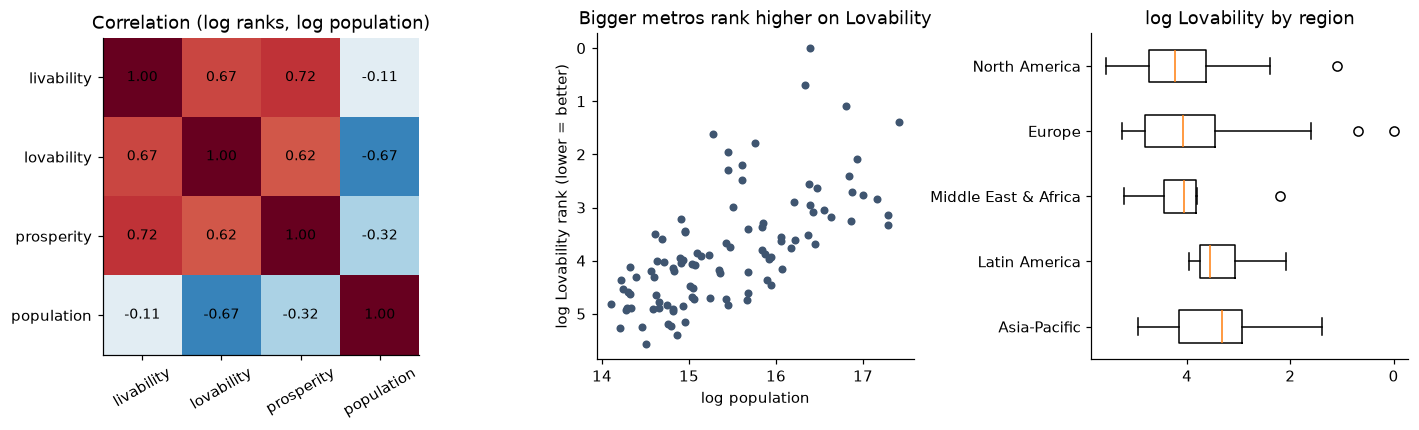

In [4]:
logs = np.log(df[['livability', 'lovability', 'prosperity', 'population']])
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
im = axes[0].imshow(logs.corr(), cmap='RdBu_r', vmin=-1, vmax=1)
axes[0].set_xticks(range(4), logs.columns, rotation=30); axes[0].set_yticks(range(4), logs.columns)
for (i, j), v in np.ndenumerate(logs.corr().values):
    axes[0].text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9)
axes[0].set_title('Correlation (log ranks, log population)')
axes[1].scatter(logs.population, logs.lovability, c=SLATE, s=18)
axes[1].set_xlabel('log population'); axes[1].set_ylabel('log Lovability rank (lower = better)'); axes[1].invert_yaxis()
axes[1].set_title('Bigger metros rank higher on Lovability')
order = df.groupby('region').lovability.median().sort_values().index
axes[2].boxplot([np.log(df.loc[df.region == r, 'lovability']) for r in order], tick_labels=order, orientation='horizontal')
axes[2].invert_xaxis(); axes[2].set_title('log Lovability by region')
plt.tight_layout(); fig.savefig(FIG / 'eda.png', bbox_inches='tight'); plt.show()

## 2. 모델 비교 — 5겹 교차 검증

타깃: `log(lovability)`. 입력: `log(livability)`, `log(prosperity)`, `log(population)`, `region`.
강점 카테고리(highlight)는 Lovability를 구성하는 항목과 겹칠 수 있어 회귀 입력에서 뺐다(누수 방지).

In [5]:
NUM = ['livability', 'prosperity', 'population']
X, y = df[NUM + ['region']], np.log(df.lovability)
pre = make_column_transformer(
    (make_pipeline(FunctionTransformer(np.log, feature_names_out='one-to-one'), StandardScaler()), NUM),
    (OneHotEncoder(handle_unknown='ignore'), ['region']))
cv = KFold(5, shuffle=True, random_state=SEED)
candidates = {
    'Mean (baseline)': DummyRegressor(),
    'Ridge': Ridge(alpha=1.0),
    'RandomForest': RandomForestRegressor(n_estimators=400, min_samples_leaf=3, random_state=SEED),
    'GradientBoosting': GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05, random_state=SEED),
}
oof, results = {}, []
for name, model in candidates.items():
    oof[name] = cross_val_predict(make_pipeline(pre, model), X, y, cv=cv)
    results.append({'model': name, 'MAE_log': mean_absolute_error(y, oof[name]), 'R2': r2_score(y, oof[name]),
                    'Spearman': spearmanr(y, oof[name])[0]})
pd.DataFrame(results).round(3)

,model,MAE_log,R2,Spearman
0,Mean (baseline),0.859,-0.055,-0.302
1,Ridge,0.375,0.802,0.864
2,RandomForest,0.360,0.816,0.878
3,GradientBoosting,0.350,0.830,0.874


### 딥러닝 비교: PyTorch MLP

표 데이터 100행에서는 신경망이 트리·선형 모델보다 불리한 경우가 많다. 같은 교차 검증으로 비교만 하고, 서빙 모델은 점수로 고른다.

In [6]:
try:
    import torch
    from torch import nn
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False
    print('torch 없음 — Colab에서는 기본 설치되어 있다. MLP 비교를 건너뛴다.')

if HAS_TORCH:
    def mlp_oof(X, y, cv, epochs=400):
        preds = np.zeros(len(y))
        for train, test in cv.split(X):
            torch.manual_seed(SEED)
            p = pre.fit(X.iloc[train])
            xt = torch.tensor(p.transform(X.iloc[train]), dtype=torch.float32)
            yt = torch.tensor(y.iloc[train].values, dtype=torch.float32).unsqueeze(1)
            net = nn.Sequential(nn.Linear(xt.shape[1], 16), nn.ReLU(), nn.Dropout(0.1), nn.Linear(16, 1))
            opt = torch.optim.AdamW(net.parameters(), lr=0.01, weight_decay=1e-3)
            for _ in range(epochs):
                opt.zero_grad(); loss = nn.functional.mse_loss(net(xt), yt); loss.backward(); opt.step()
            net.eval()
            with torch.no_grad():
                preds[test] = net(torch.tensor(p.transform(X.iloc[test]), dtype=torch.float32)).squeeze(1).numpy()
        return preds
    oof['MLP (PyTorch)'] = mlp_oof(X, y, cv)
    results.append({'model': 'MLP (PyTorch)', 'MAE_log': mean_absolute_error(y, oof['MLP (PyTorch)']),
                    'R2': r2_score(y, oof['MLP (PyTorch)']), 'Spearman': spearmanr(y, oof['MLP (PyTorch)'])[0]})
scores = pd.DataFrame(results).sort_values('MAE_log').round(3)
scores

,model,MAE_log,R2,Spearman
4,MLP (PyTorch),0.343,0.817,0.870
3,GradientBoosting,0.350,0.830,0.874
2,RandomForest,0.360,0.816,0.878
1,Ridge,0.375,0.802,0.864
0,Mean (baseline),0.859,-0.055,-0.302


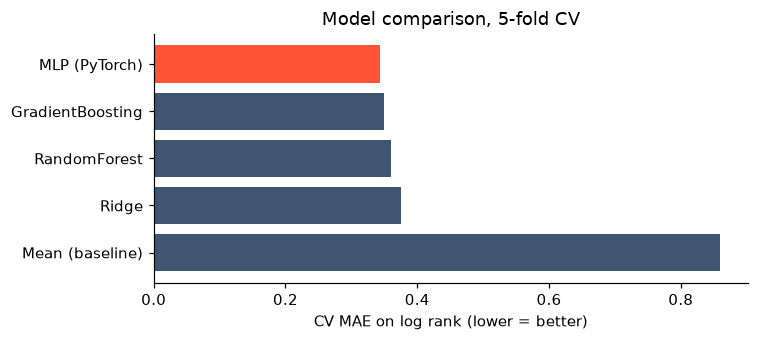

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.2))
s = scores.sort_values('MAE_log', ascending=False)
ax.barh(s.model, s.MAE_log, color=[ACCENT if m == scores.iloc[0].model else SLATE for m in s.model])
ax.set_xlabel('CV MAE on log rank (lower = better)'); ax.set_title('Model comparison, 5-fold CV')
plt.tight_layout(); fig.savefig(FIG / 'model_comparison.png', bbox_inches='tight'); plt.show()

**서빙 모델 선택.** 표 모델과 MLP의 차이는 MAE 0.01 안팎으로 교차 검증 잡음 수준이다. 서빙에는 torch 없이 joblib 파일 하나로 불러올 수 있는 scikit-learn 모델 가운데 MAE가 가장 낮은 것을 쓴다(아래 `BEST`). 결과는 `ml/models/model_card.json`에 모든 모델 점수와 함께 남긴다.

## 3. 기회 점수 — 기대보다 문화 매력이 앞선 도시

`opportunity = 예측 log 순위 − 실제 log 순위`. 양수면 경제·정주·인구로 기대되는 것보다 문화 매력 순위가 좋다.
예측은 해당 도시를 학습에 쓰지 않은 out-of-fold 값이다.

In [8]:
SKLEARN_MODELS = [m for m in scores.model if m in candidates and m != 'Mean (baseline)']
BEST = SKLEARN_MODELS[0]
df['predicted_lovability'] = np.exp(oof[BEST]).round(1)
df['opportunity'] = (oof[BEST] - y).round(3)
top = df.sort_values('opportunity', ascending=False)
print('서빙 모델:', BEST)
top[['rank', 'city', 'country', 'lovability', 'predicted_lovability', 'opportunity']].head(15)

서빙 모델: GradientBoosting


,rank,city,country,lovability,predicted_lovability,opportunity
54,55,Las Vegas,USA,36,129.3,1.279
7,8,Dubai,UAE,9,29.7,1.194
61,62,Orlando,USA,52,146.1,1.033
17,18,São Paulo,Brazil,8,21.7,0.999
2,3,Paris,France,1,2.6,0.958
29,30,Mexico City,Mexico,11,25.6,0.846
75,76,Medellín,Colombia,49,101.3,0.726
85,86,Abu Dhabi,UAE,94,175.2,0.623
73,74,Athens,Greece,47,85.9,0.603
37,38,Prague,Czechia,33,58.7,0.576


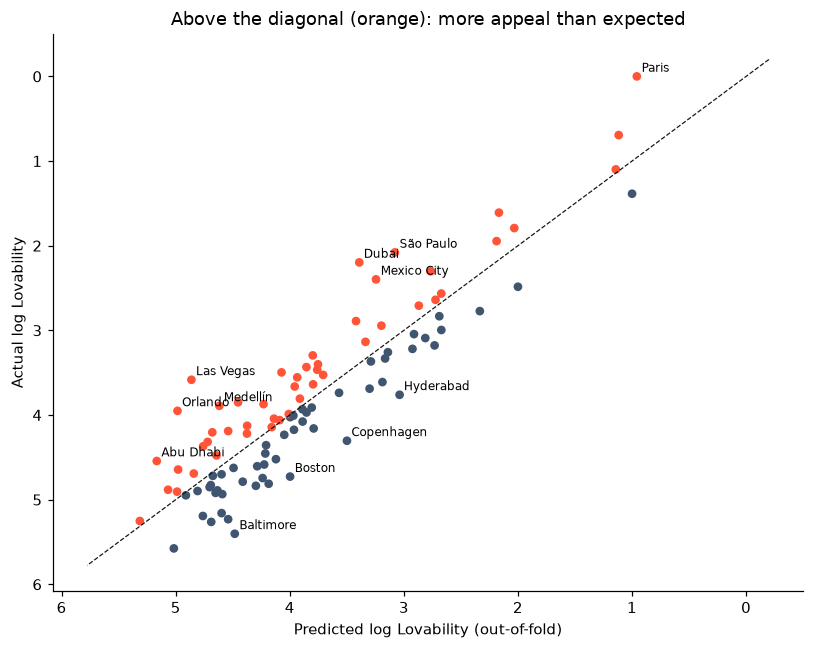

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter(oof[BEST], y, c=np.where(df.opportunity > 0, ACCENT, SLATE), s=22)
lims = [y.min() - .2, y.max() + .2]; ax.plot(lims, lims, color=INK, lw=.8, ls='--')
for _, r in pd.concat([top.head(8), top.tail(4)]).iterrows():
    ax.annotate(r.city, (np.log(r.predicted_lovability), np.log(r.lovability)), fontsize=8, xytext=(3, 3), textcoords='offset points')
ax.set_xlabel('Predicted log Lovability (out-of-fold)'); ax.set_ylabel('Actual log Lovability')
ax.invert_xaxis(); ax.invert_yaxis(); ax.set_title('Above the diagonal (orange): more appeal than expected')
plt.tight_layout(); fig.savefig(FIG / 'opportunity.png', bbox_inches='tight'); plt.show()

## 4. 서빙용 모델 저장 (joblib)

In [10]:
final = make_pipeline(pre, candidates[BEST]).fit(X, y)
joblib.dump(final, MODELS / 'lovability_model.joblib')
meta = {
    'trained_at': datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds'),
    'data': 'ml/data/world_cities_2026.csv (Resonance World\'s Best Cities 2026, 100 cities)',
    'target': 'log(lovability rank)', 'features': NUM + ['region'], 'model': BEST,
    'cv': '5-fold KFold(shuffle, seed=42)',
    'sklearn_version': __import__('sklearn').__version__,
    'scores': scores.to_dict(orient='records'),
}
(MODELS / 'model_card.json').write_text(json.dumps(meta, ensure_ascii=False, indent=1), encoding='utf-8')
print(json.dumps(meta['scores'], indent=1))

[
 {
  "model": "MLP (PyTorch)",
  "MAE_log": 0.343,
  "R2": 0.817,
  "Spearman": 0.87
 },
 {
  "model": "GradientBoosting",
  "MAE_log": 0.35,
  "R2": 0.83,
  "Spearman": 0.874
 },
 {
  "model": "RandomForest",
  "MAE_log": 0.36,
  "R2": 0.816,
  "Spearman": 0.878
 },
 {
  "model": "Ridge",
  "MAE_log": 0.375,
  "R2": 0.802,
  "Spearman": 0.864
 },
 {
  "model": "Mean (baseline)",
  "MAE_log": 0.859,
  "R2": -0.055,
  "Spearman": -0.302
 }
]


## 5. 도시 유형 — 비지도 군집

세 축 순위와 인구(로그·표준화)로 KMeans. k는 실루엣 점수로 3~6 중에서 고른다.

In [11]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

CF = ['livability', 'lovability', 'prosperity', 'population']
scaler = make_pipeline(FunctionTransformer(np.log), StandardScaler())
Z = scaler.fit_transform(df[CF])
sil = {k: silhouette_score(Z, KMeans(k, n_init=20, random_state=SEED).fit_predict(Z)) for k in range(3, 7)}
K = max(sil, key=sil.get)
cluster_model = make_pipeline(FunctionTransformer(np.log), StandardScaler(), KMeans(K, n_init=20, random_state=SEED)).fit(df[CF])
df['cluster'] = cluster_model.predict(df[CF])
pca = PCA(2, random_state=SEED).fit(Z)
df[['pca_x', 'pca_y']] = pca.transform(Z).round(3)
joblib.dump({'cluster': cluster_model, 'pca': make_pipeline(scaler, pca), 'features': CF}, MODELS / 'city_clusters.joblib')
print('silhouette', {k: round(v, 3) for k, v in sil.items()}, '→ k =', K)
df.groupby('cluster')[CF].median().round(0).assign(cities=df.groupby('cluster').city.apply(lambda s: ', '.join(s.head(5))))

silhouette {3: 0.37, 4: 0.34, 5: 0.354, 6: 0.349} → k = 3


,livability,lovability,prosperity,population,cities
cluster,,,,,
0,58.0,96.0,62.0,2726500.0,"Melbourne, Oslo, Stockholm, Vienna, San Francisco"
1,95.0,34.0,52.0,10891000.0,"São Paulo, Hong Kong, Istanbul, Bangkok, Osaka"
2,9.0,10.0,9.0,7605000.0,"London, New York, Paris, Tokyo, Madrid"


## 6. 딥러닝 — 소개 글 임베딩으로 비슷한 도시 찾기

`sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`(사전학습 다국어 문장 임베딩)로 도시 소개 글을 384차원 벡터로 바꾸고, 코사인 유사도 상위 5개 도시를 저장한다.
소개 글은 Resonance의 저작물이라 저장소에 올리지 않는다(`ml/data/private/`). 결과로는 도시 이름과 유사도만 저장한다.

In [12]:
NARR = DATA / 'private' / 'narratives_2026.jsonl'
try:
    from sentence_transformers import SentenceTransformer
    HAS_ST = NARR.exists()
    if not NARR.exists():
        print('소개 글 파일이 없다: python ml/scripts/extract_resonance.py 로 만든 뒤 다시 실행')
except ImportError:
    HAS_ST = False
    print('sentence-transformers 없음 — pip install sentence-transformers')

if HAS_ST:
    texts = pd.read_json(NARR, lines=True).sort_values('rank')
    encoder = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')
    E = encoder.encode(texts.text.tolist(), normalize_embeddings=True, show_progress_bar=False)
    S = E @ E.T
    np.fill_diagonal(S, -1)
    similar = {texts.city.iloc[i]: [{'city': texts.city.iloc[j], 'similarity': round(float(S[i, j]), 3)}
                                    for j in np.argsort(-S[i])[:5]] for i in range(len(texts))}
    (DATA / 'similar_cities_2026.json').write_text(json.dumps(similar, ensure_ascii=False, indent=1), encoding='utf-8')
    print('Seoul →', [s['city'] for s in similar['Seoul']])
    print('Berlin →', [s['city'] for s in similar['Berlin']])

C:\myproject\_aci_readme\ml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  21%|██        | 42/199 [00:00<00:00, 418.33it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1437.51it/s]

Seoul → ['Hong Kong', 'Busan', 'Beijing', 'Taipei', 'Munich']
Berlin → ['Hamburg', 'The Ruhr', 'Copenhagen', 'Munich', 'Stockholm']


## 7. 결과 저장 → Streamlit

In [13]:
out = df[['rank', 'city', 'country', 'region', 'population', 'livability', 'lovability', 'prosperity',
          'highlight1', 'highlight1_rank', 'highlight2', 'highlight2_rank',
          'predicted_lovability', 'opportunity', 'cluster', 'pca_x', 'pca_y']]
out.to_csv(DATA / 'city_scores_2026.csv', index=False)
ours = ['Seoul', 'Berlin', 'London', 'New York', 'Mexico City', 'Melbourne', 'Amsterdam', 'Beijing', 'Barcelona',
        'Chicago', 'Dubai', 'Hong Kong', 'Paris', 'Tokyo', 'Shanghai', 'Singapore']
out[out.city.isin(ours)].sort_values('opportunity', ascending=False)[['city', 'lovability', 'predicted_lovability', 'opportunity', 'cluster']]

,city,lovability,predicted_lovability,opportunity,cluster
7,Dubai,9,29.7,1.194,2
2,Paris,1,2.6,0.958,2
29,Mexico City,11,25.6,0.846,1
18,Hong Kong,27,44.6,0.503,1
8,Berlin,10,15.9,0.463,2
0,London,2,3.1,0.424,2
9,Barcelona,7,8.9,0.241,2
14,Beijing,15,17.6,0.161,2
34,Chicago,38,44.5,0.158,1
1,New York,3,3.1,0.043,2


## 8. 형식별 가중치 학습 — 공개 관람객 데이터

팝업·비상설 전시·상설 전시 적합도는 0–1로 맞춘 구성 요소(문화 매력·정주·경제·인구·기회 점수·강점 신호)의 가중합이다. 가중치를 손으로 정하지 않고, 형식마다 공개된 관람객 지표를 정답으로 학습한다.

| 형식 | 정답(대체 지표) | 출처 |
| --- | --- | --- |
| 팝업 | 국제 방문객 수 | Euromonitor Top 100 City Destinations 2018 (일부 Mastercard 2016) |
| 비상설 전시 | 도시 미술관 연간 관람객 합 | The Art Newspaper Visitor Figures 2025, 상위 150개 |
| 상설 전시 | 상위 150 안의 미술관 수 | 같은 자료 |

방법: 음수가 없는 최소제곱(NNLS)으로 가중치를 구하고 합을 1로 맞춘다. 반복 5겹 교차 검증에서 처음의 설계 가중치와 순위 상관(Spearman)을 비교한다. 목록에 없는 도시는 목록의 최솟값보다 아래로 둔다.

In [14]:
sys.path[:0] = ['ml/scripts', 'ml/app']
import build_format_targets, learn_format_weights
if not (DATA / 'format_targets_2026.csv').exists():
    build_format_targets.main()  # 원자료를 내려받아 ml/data/private/sources에 두고 도시별 수치만 저장
targets = pd.read_csv(DATA / 'format_targets_2026.csv')
fw = learn_format_weights.learn(out, targets)
(MODELS / 'format_weights.json').write_text(json.dumps(fw, ensure_ascii=False, indent=1), encoding='utf-8')
pd.DataFrame({k: {'target': v['target'], 'listed': v['cities_listed'], 'CV rho (learned)': v['cv_spearman']['learned'],
                  'CV rho (design)': v['cv_spearman']['design']} for k, v in fw['formats'].items()}).T

,target,listed,CV rho (learned),CV rho (design)
popup,국제 방문객 수,74,0.699,0.605
temporary,미술관 연간 관람객 합,45,0.564,0.434
permanent,상위 150 안의 미술관 수,45,0.576,0.466


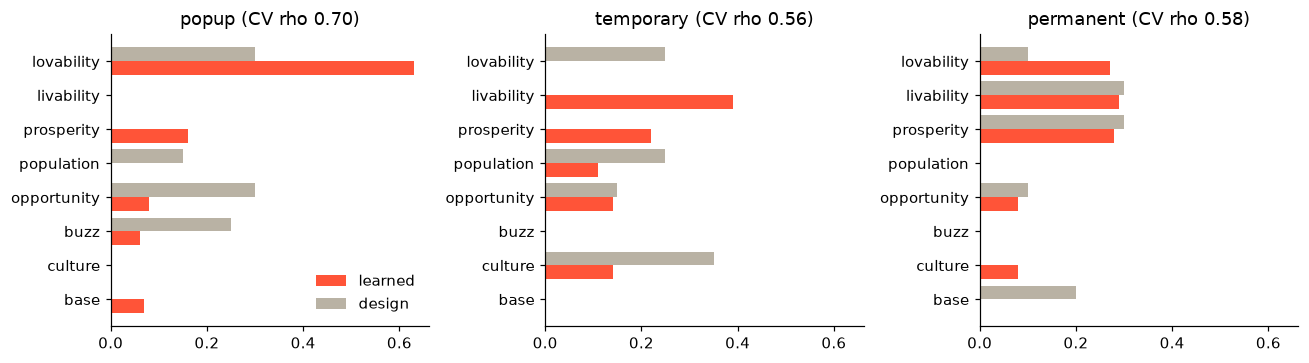

target correlation (Spearman)


,popup,temporary,permanent
popup,1.00,0.43,0.42
temporary,0.43,1.00,0.98
permanent,0.42,0.98,1.00


In [15]:
from formats import DESIGN_WEIGHTS
names = ['lovability', 'livability', 'prosperity', 'population', 'opportunity', 'buzz', 'culture', 'base']
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharex=True)
for ax, (key, spec) in zip(axes, fw['formats'].items()):
    yy = np.arange(len(names))
    ax.barh(yy + 0.2, [spec['weights'].get(n, 0) for n in names], 0.4, color=ACCENT, label='learned')
    ax.barh(yy - 0.2, [DESIGN_WEIGHTS[key].get(n, 0) for n in names], 0.4, color='#B9B2A4', label='design')
    ax.set_yticks(yy, names); ax.invert_yaxis(); ax.set_title(f"{key} (CV rho {spec['cv_spearman']['learned']:.2f})")
axes[0].legend(frameon=False)
plt.tight_layout(); fig.savefig(FIG / 'format_weights.png', bbox_inches='tight'); plt.show()
print('target correlation (Spearman)'); pd.DataFrame(fw['target_correlation'])

## 한계

- 표본 100개 도시, 한 해(2026) 단면. 순위 데이터라 간격 정보가 없다.
- 기회 점수는 '문화 매력이 경제 규모보다 앞선 정도'이지, 팝업 성과를 예측한 값이 아니다. 실제 팝업 방문·매출과 비교해 검증해야 한다.
- 형식별 가중치의 정답은 방문객·미술관 관람객이라는 대체 지표다. 큰 유명 도시가 위로 오고, 비상설과 상설의 정답이 서로 매우 비슷하다(순위 상관 0.98). 실제 팝업·전시 성과로 다시 학습해야 한다(로드맵 G1).
- 바젤·베네치아는 인구 기준(100만 명) 미달로 세계 표에 없어 이 모델의 대상이 아니다.